In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/robinaz/crypto/crypto.csv


# **Python Practice: Time Series Model Building and Volatility**

Last week we estimated MA(1), AR(1) and ARMA(1,1) models for BTC returns, and found that the past tells us very little about the **average** return. This week:

**Part 1:** choose the best model (Box–Jenkins + AIC/SBIC) and check it.
**Part 2:** model the **risk** of BTC (volatility) with ARCH and GARCH.

## **Step 1: Import the Libraries**

New this week:
- `arch_model` estimates ARCH and GARCH models.
- `het_arch` is the ARCH test.

If Kaggle says `No module named 'arch'`, turn **Internet on** and run `!pip install arch` in a new cell.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
!pip install arch -q
from arch import arch_model
import warnings
warnings.filterwarnings("ignore")

## **Step 2: Upload the Data and Compute Returns**

In [3]:
df = pd.read_csv("/kaggle/input/datasets/robinaz/crypto/crypto.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df = df.set_index("Date")
df.head()

,BTC
Date,
2015-01-01,201.7391
2015-01-02,205.5674
2015-01-03,183.4140
2015-01-04,172.8799
2015-01-05,179.9004


# Returns

In [4]:
returns = np.log(df["BTC"]).diff().dropna() * 100
returns.head()

Date
2015-01-02     1.879868
2015-01-03   -11.402807
2015-01-04    -5.914876
2015-01-05     3.980623
2015-01-06     4.975838
Name: BTC, dtype: float64

---
# **Part 1: Building the Model (Box–Jenkins)**

The Box–Jenkins approach has three steps:
1. **Identify:** look at the ACF and PACF (done in Week 8).
2. **Estimate:** fit the models (done in Week 9).
3. **Check:** make sure no autocorrelation is left in the residuals.

Before checking, we **choose** the best model using AIC and SBIC.

## **Step 3: Estimate the Models**

We add ARMA(0,0), the "no pattern" model: return = average + shock. It is written `order=(0, 0, 0)`.

In [5]:
arma00 = ARIMA(returns, order=(0, 0, 0)).fit()
ma1 = ARIMA(returns, order=(0, 0, 1)).fit()
ar1 = ARIMA(returns, order=(1, 0, 0)).fit()
arma11 = ARIMA(returns, order=(1, 0, 1)).fit()

## **Step 4: Choose the Best Model – AIC and SBIC**

AIC and SBIC = how well the model fits + a penalty for each extra coefficient.

- **Lower is better.**
- SBIC gives a bigger penalty, so it prefers **smaller** models.

Python calls SBIC `bic`.

In [6]:
ic_table = pd.DataFrame({
    "AIC": [arma00.aic, ma1.aic, ar1.aic, arma11.aic],
    "SBIC": [arma00.bic, ma1.bic, ar1.bic, arma11.bic],
}, index=["ARMA(0,0)", "MA(1)", "AR(1)", "ARMA(1,1)"]).round(2)
ic_table

,AIC,SBIC
"ARMA(0,0)",21540.26,21552.85
MA(1),21540.24,21559.14
AR(1),21540.19,21559.09
"ARMA(1,1)",21541.91,21567.10


**Interpretation:**
- **Lowest AIC: AR(1)** (21540.19). The difference from MA(1) (21540.24) and ARMA(0,0) (21540.26) is **tiny**, less than 0.1.
- **Lowest SBIC: ARMA(0,0)** (21552.85), by a clear margin of about 6 points.
- AIC and SBIC **disagree**. AIC gives a small penalty, so the tiny lag 1 effect is just enough to win. SBIC gives a bigger penalty, so the tiny effect is **not worth** the extra coefficient.
- **ARMA(1,1)** is the **worst** on both: its extra coefficients add nothing.

We follow **SBIC**, so our best model is **ARMA(0,0)**:

$r_t = \mu + u_t$

BTC's return today = average return (0.14%) + a random shock. The best forecast for tomorrow is simply the **average return**. This matches Week 8 (Ljung–Box p = 0.055) and Week 9 (tiny coefficients).

## **Step 5: Estimate an ARIMA(1,1,1) Model on Prices**

So far we used **returns**, because prices are non-stationary. An ARIMA model can be applied **directly to prices**.

ARIMA(p, **d**, q):
- **p = 1**: one past value (AR part)
- **d = 1**: Python takes the **first difference itself**, turning prices into returns
- **q = 1**: one past shock (MA part)

So we do **not** need to compute returns first. We give the model the log price, and it does the differencing for us. We multiply by 100 so the results are in %, like our returns.

In [7]:
log_price = np.log(df["BTC"]) * 100

arima111 = ARIMA(log_price, order=(1, 1, 1)).fit()
print(arima111.summary())

                               SARIMAX Results                                
Dep. Variable:                    BTC   No. Observations:                 4018
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -10770.403
Date:                Sat, 14 Nov 2026   AIC                          21546.806
Time:                        22:56:55   BIC                          21565.701
Sample:                    01-01-2015   HQIC                         21553.503
                         - 12-31-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3024      0.492     -0.615      0.539      -1.266       0.662
ma.L1          0.2805      0.493      0.569      0.569      -0.686       1.247
sigma2        12.4855      0.110    113.640      0.0

**How to read the table:**

| Row | Meaning |
|---|---|
| `ar.L1` | φ₁, the effect of yesterday's return |
| `ma.L1` | θ₁, the effect of yesterday's shock |
| `sigma2` | the variance of the shocks |

There is no `const`: with d = 1, Python leaves out the average return by default.

**Interpretation:** Compare these numbers with the **ARMA(1,1) on returns** from Week 9. They are **almost the same**, because an ARIMA(1,1,1) on prices **is** an ARMA(1,1) on returns: Python just takes the first difference for us.

Look at the p-values of `ar.L1` and `ma.L1`. If they are above 0.05, the model finds **no significant pattern**, exactly as in Week 9.

In [13]:
print("phi_1 (ar.L1):  ", round(arima111.params["ar.L1"], 4), "  p-value:", round(arima111.pvalues["ar.L1"], 4))
print("theta_1 (ma.L1):", round(arima111.params["ma.L1"], 4), "  p-value:", round(arima111.pvalues["ma.L1"], 4))
print("sigma2:         ", round(arima111.params["sigma2"], 4))

phi_1 (ar.L1):   -0.3024   p-value: 0.5388
theta_1 (ma.L1): 0.2805   p-value: 0.5693
sigma2:          12.4855


**Interpretation:**
- **φ₁ (ar.L1) = [ ] (p = [ ])**: the effect of yesterday's return on today's return.
- **θ₁ (ma.L1) = [ ] (p = [ ])**: the effect of yesterday's shock on today's return.
- **sigma2 = [ ]**: the variance of the shocks.

Compare with the **ARMA(1,1) on returns** in Week 9 (φ₁ = −0.2705, θ₁ = 0.2473, sigma2 = 12.46). The numbers are almost the same, because an ARIMA(1,1,1) on prices **is** an ARMA(1,1) on returns: Python takes the first difference for us.

---
# **Part 2: Modelling Volatility**

The **average** BTC return is hard to predict. But what about the **risk**: how much BTC moves?

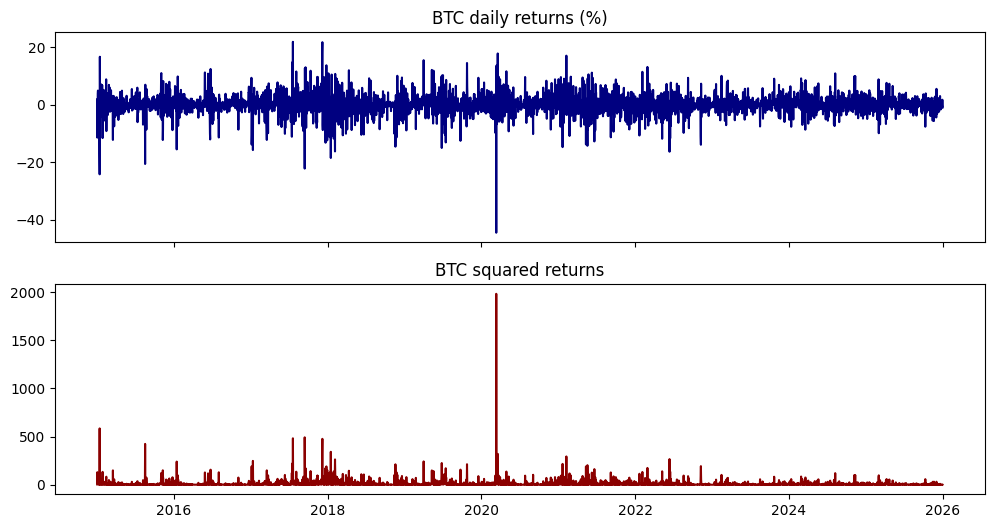

In [8]:
squared = returns ** 2

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(returns, color="navy")
axes[0].set_title("BTC daily returns (%)")
axes[1].plot(squared, color="darkred")
axes[1].set_title("BTC squared returns")
plt.show()

**Interpretation:** Big moves come **together**. Calm periods follow calm periods, and wild periods follow wild periods. The biggest spike is the COVID crash in March 2020. This is **volatility clustering**.

## **Step 7: Ljung–Box Test on Squared Returns**

In Week 8, returns had **no** significant autocorrelation (p = 0.055). Now we test the **squared** returns.

- H₀: There is no autocorrelation.
- H₁: There is autocorrelation.
- If p-value < 0.05 → reject H₀ → autocorrelated.

In [9]:
print("Ljung-Box p-value, returns:        ", round(acorr_ljungbox(returns, lags=[10])["lb_pvalue"].iloc[0], 4))
print("Ljung-Box p-value, squared returns:", round(acorr_ljungbox(squared, lags=[10])["lb_pvalue"].iloc[0], 4))

Ljung-Box p-value, returns:         0.055
Ljung-Box p-value, squared returns: 0.0


**Interpretation:** Returns: no significant autocorrelation. Squared returns: strong autocorrelation (p-value below 0.05). The **direction** of BTC is hard to predict, but the **size** of its moves (the risk) **is** predictable.

## **Step 8: The ARCH Test**

- H₀: No ARCH effects (the variance is constant).
- H₁: ARCH effects (volatility clusters).
- If p-value < 0.05 → reject H₀ → we need a volatility model.

In [10]:
arch_test = het_arch(returns - returns.mean(), nlags=5)
print("ARCH test p-value:", round(arch_test[1], 4))

ARCH test p-value: 0.0


## **Step 9: Estimate an ARCH(1) Model**

$\sigma_t^2 = \alpha_0 + \alpha_1 u_{t-1}^2$

Today's variance = a constant + a share α₁ of **yesterday's squared shock**.

In [11]:
arch1 = arch_model(returns, mean="Constant", vol="ARCH", p=1).fit(disp="off")
print(arch1.summary())

                      Constant Mean - ARCH Model Results                      
Dep. Variable:                    BTC   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:               -10650.0
Distribution:                  Normal   AIC:                           21306.1
Method:            Maximum Likelihood   BIC:                           21325.0
                                        No. Observations:                 4017
Date:                Sat, Nov 14 2026   Df Residuals:                     4016
Time:                        23:01:24   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1469  5.350e-02      2.747  6.019e-03 [4.209e-0

## **Step 10: Estimate a GARCH(1,1) Model**

$\sigma_t^2 = \alpha_0 + \alpha_1 u_{t-1}^2 + \beta \sigma_{t-1}^2$

Today's risk = constant + yesterday's shock + **yesterday's risk**.

In [12]:
garch11 = arch_model(returns, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
print(garch11.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                    BTC   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -10366.0
Distribution:                  Normal   AIC:                           20740.1
Method:            Maximum Likelihood   BIC:                           20765.3
                                        No. Observations:                 4017
Date:                Sat, Nov 14 2026   Df Residuals:                     4016
Time:                        23:02:03   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1544  4.566e-02      3.381  7.210e-04 [6.491e-0

**How to read the table:** the same as ARCH, plus one new row:

| Row | Symbol | Meaning |
|---|---|---|
| `beta[1]` | β | Effect of yesterday's risk (memory) |

**Interpretation:** α₁ (news) is usually small and β (memory) is usually large. Most of today's risk is carried over from yesterday's risk. If α₁ + β is close to 1, a volatility shock lasts a **long time**.

## **Conclusion**

| Step | What we found |
|---|---|
| AIC / SBIC | SBIC chose **ARMA(0,0)**: the best forecast is the average return |
| ARIMA(1,1,1) on prices | Python takes the first difference itself; same result as ARMA(1,1) on returns |
| Squared returns + ARCH test | BTC volatility is **not constant**: it comes in clusters |
| ARCH(1) | Yesterday's shock raises today's risk |
| GARCH(1,1) | Yesterday's risk also matters: risk has a long memory |

- The **average** BTC return is hard to predict.
- The **risk** of BTC is predictable: big moves follow big moves.